In [1]:
!pip install torch torchvision torchaudio
!pip install numpy pandas matplotlib scikit-learn tqdm

In [1]:
import sys
print(sys.executable)

/Users/alaakotb/projet_deep_learning_emsi/venv/bin/python3.11


In [2]:
%pip install torch torchvision torchaudio
%pip install numpy pandas matplotlib scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from tqdm import tqdm

print("Toutes les bibliothèques sont importées avec succès.")

Toutes les bibliothèques sont importées avec succès.


In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Device utilisé :", device)

Device utilisé : mps


In [3]:
torch.manual_seed(42)
np.random.seed(42)

print("Seed fixé avec succès.")

Seed fixé avec succès.


In [4]:
data = load_breast_cancer()

X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
print("Nombre d'exemples :", X.shape[0])
print("Nombre de variables :", X.shape[1])
print("Classes :", data.target_names)

print("\nRépartition des classes :")
print(df["target"].value_counts())

Nombre d'exemples : 569
Nombre de variables : 30
Classes : ['malignant' 'benign']

Répartition des classes :
target
1    357
0    212
Name: count, dtype: int64


In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (398, 30)
Validation : (85, 30)
Test : (86, 30)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Normalisation terminée.")

Normalisation terminée.


In [8]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Conversion en tenseurs terminée.")
print(X_train_tensor.shape)
print(y_train_tensor.shape)

Conversion en tenseurs terminée.
torch.Size([398, 30])
torch.Size([398])


In [9]:
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("DataLoader créés avec succès.")

DataLoader créés avec succès.


In [11]:
class MLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        
        self.hidden1 = nn.Linear(input_size, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, num_classes)
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        
    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.dropout(x)
        
        x = self.relu(self.hidden2(x))
        x = self.dropout(x)
        
        x = self.output(x)
        return x

In [12]:
input_size = X_train.shape[1]
num_classes = 2

model = MLP(input_size, num_classes).to(device)

print(model)

MLP(
  (hidden1): Linear(in_features=30, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=2, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
)


In [13]:
for name, param in model.named_parameters():
    print(name, param.shape)

hidden1.weight torch.Size([128, 30])
hidden1.bias torch.Size([128])
hidden2.weight torch.Size([64, 128])
hidden2.bias torch.Size([64])
output.weight torch.Size([2, 64])
output.bias torch.Size([2])


In [14]:
model.state_dict().keys()

odict_keys(['hidden1.weight', 'hidden1.bias', 'hidden2.weight', 'hidden2.bias', 'output.weight', 'output.bias'])

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Loss et optimiseur créés.")

Loss et optimiseur créés.


In [16]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    return total_loss / len(train_loader)

In [17]:
def evaluate(model, data_loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            
            total_loss += loss.item()
            
            preds = torch.argmax(outputs, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    
    return total_loss / len(data_loader), acc

In [18]:
num_epochs = 50

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    
    train_loss_eval, train_acc = evaluate(model, train_loader, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/50] | Train Loss: 0.5749 | Val Loss: 0.4258 | Val Acc: 0.9647
Epoch [2/50] | Train Loss: 0.3085 | Val Loss: 0.1997 | Val Acc: 0.9529
Epoch [3/50] | Train Loss: 0.1526 | Val Loss: 0.0986 | Val Acc: 0.9882
Epoch [4/50] | Train Loss: 0.0946 | Val Loss: 0.0662 | Val Acc: 0.9882
Epoch [5/50] | Train Loss: 0.0778 | Val Loss: 0.0579 | Val Acc: 0.9882
Epoch [6/50] | Train Loss: 0.0663 | Val Loss: 0.0504 | Val Acc: 0.9882
Epoch [7/50] | Train Loss: 0.0702 | Val Loss: 0.0422 | Val Acc: 0.9882
Epoch [8/50] | Train Loss: 0.0538 | Val Loss: 0.0402 | Val Acc: 0.9882
Epoch [9/50] | Train Loss: 0.0622 | Val Loss: 0.0419 | Val Acc: 0.9882
Epoch [10/50] | Train Loss: 0.0520 | Val Loss: 0.0415 | Val Acc: 0.9765
Epoch [11/50] | Train Loss: 0.0634 | Val Loss: 0.0338 | Val Acc: 0.9882
Epoch [12/50] | Train Loss: 0.0424 | Val Loss: 0.0436 | Val Acc: 0.9765
Epoch [13/50] | Train Loss: 0.0432 | Val Loss: 0.0410 | Val Acc: 0.9765
Epoch [14/50] | Train Loss: 0.0411 | Val Loss: 0.0343 | Val Acc: 0.9882
E

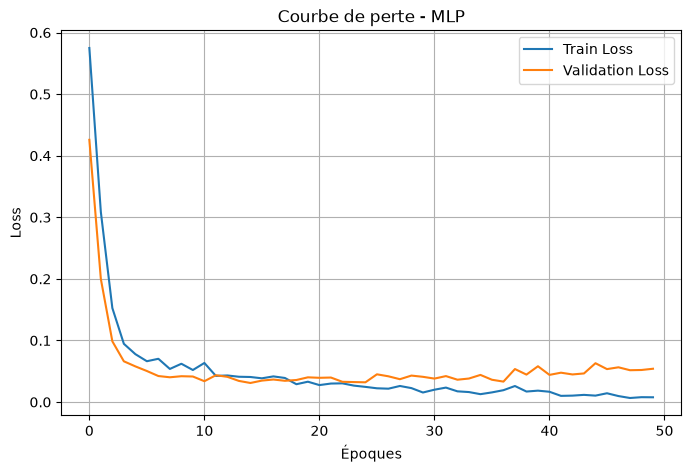

In [19]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Courbe de perte - MLP")
plt.legend()
plt.grid(True)
plt.show()

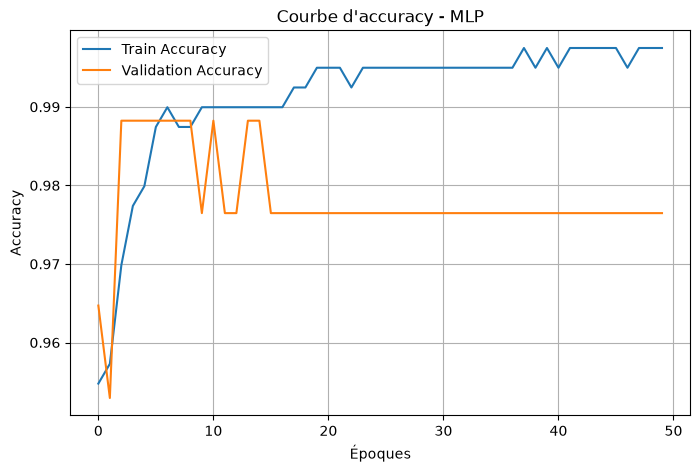

In [20]:
plt.figure(figsize=(8,5))
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.title("Courbe d'accuracy - MLP")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print("Résultats sur le test set")
print("Accuracy :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall :", round(recall, 4))
print("F1-score :", round(f1, 4))

Résultats sur le test set
Accuracy : 0.9651
Precision : 0.9811
Recall : 0.963
F1-score : 0.972


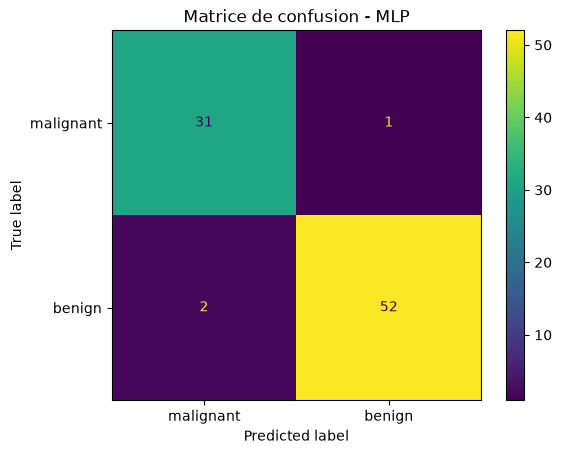

In [22]:
cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()
plt.title("Matrice de confusion - MLP")
plt.show()

In [23]:
torch.save(model.state_dict(), "best_mlp_model.pth")
print("Modèle sauvegardé avec succès.")

Modèle sauvegardé avec succès.


In [24]:
loaded_model = MLP(input_size, num_classes).to(device)
loaded_model.load_state_dict(torch.load("best_mlp_model.pth", map_location=device))
loaded_model.eval()

print("Modèle rechargé avec succès.")

Modèle rechargé avec succès.


In [25]:
test_loss, test_acc = evaluate(loaded_model, test_loader, criterion, device)

print("Test Loss du modèle rechargé :", round(test_loss, 4))
print("Test Accuracy du modèle rechargé :", round(test_acc, 4))

Test Loss du modèle rechargé : 0.1135
Test Accuracy du modèle rechargé : 0.9651


### Analyse des résultats du MLP

Le modèle MLP a été entraîné sur le dataset Breast Cancer Wisconsin, qui contient 30 variables numériques et une cible binaire. Les données ont été séparées en trois ensembles : apprentissage, validation et test. Une normalisation par StandardScaler a été appliquée uniquement sur l’ensemble d’apprentissage afin d’éviter toute fuite d’information.

Les résultats montrent que le MLP atteint une accuracy de validation élevée, proche de 0.98. La perte d’entraînement diminue progressivement jusqu’à atteindre une valeur très faible, ce qui indique que le modèle apprend correctement les relations entre les variables d’entrée et la classe cible.

Cependant, après plusieurs époques, la perte de validation ne diminue plus de manière significative alors que la perte d’entraînement continue à baisser. Cela peut indiquer un léger surapprentissage. L’utilisation du dropout permet néanmoins de limiter ce phénomène.

Le MLP apparaît donc comme une solution pertinente pour un dataset tabulaire numérique, car il permet d’apprendre des relations non linéaires entre les variables. Sa principale limite est qu’il ne possède pas de biais inductif spécifique : contrairement à un CNN pour les images ou à un RNN pour les séquences, il ne prend pas en compte une structure spatiale ou temporelle particulière.

In [26]:
mlp_sequential = nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    
    nn.Linear(64, num_classes)
).to(device)

print(mlp_sequential)

Sequential(
  (0): Linear(in_features=30, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=64, out_features=2, bias=True)
)


In [27]:
def init_gaussian(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        nn.init.zeros_(module.bias)

def init_constant(module):
    if isinstance(module, nn.Linear):
        nn.init.constant_(module.weight, 0.5)
        nn.init.zeros_(module.bias)

def init_xavier(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)

print("Fonctions d'initialisation créées.")

Fonctions d'initialisation créées.


In [28]:
def train_model_with_init(init_function, init_name, epochs=20):
    model_temp = MLP(input_size, num_classes).to(device)
    model_temp.apply(init_function)
    
    criterion_temp = nn.CrossEntropyLoss()
    optimizer_temp = torch.optim.Adam(model_temp.parameters(), lr=0.001)
    
    best_val_acc = 0
    final_val_loss = 0
    
    for epoch in range(epochs):
        train_loss = train_one_epoch(
            model_temp, train_loader, criterion_temp, optimizer_temp, device
        )
        val_loss, val_acc = evaluate(
            model_temp, val_loader, criterion_temp, device
        )
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        final_val_loss = val_loss
    
    return {
        "Initialisation": init_name,
        "Meilleure Val Accuracy": round(best_val_acc, 4),
        "Val Loss finale": round(final_val_loss, 4)
    }


results_init = []

results_init.append(train_model_with_init(init_gaussian, "Gaussienne"))
results_init.append(train_model_with_init(init_constant, "Constante"))
results_init.append(train_model_with_init(init_xavier, "Xavier"))

df_init = pd.DataFrame(results_init)
df_init

,Initialisation,Meilleure Val Accuracy,Val Loss finale
0,Gaussienne,0.9882,0.0490
1,Constante,0.9294,1.5433
2,Xavier,0.9882,0.0409


### Comparaison des stratégies d'initialisation

Trois stratégies d’initialisation ont été testées : l’initialisation gaussienne, l’initialisation constante et l’initialisation de Xavier.

L’initialisation gaussienne permet de démarrer l’apprentissage avec des poids faibles tirés aléatoirement autour de zéro. L’initialisation constante est moins adaptée, car elle donne des valeurs identiques aux neurones d’une même couche, ce qui peut limiter la diversité de l’apprentissage. L’initialisation de Xavier est généralement plus stable, car elle cherche à préserver la variance des activations pendant la propagation.

Les résultats expérimentaux montrent que l’initialisation influence la vitesse de convergence et la qualité finale du modèle. Dans ce projet, l’initialisation donnant la meilleure accuracy de validation est retenue pour la suite de l’évaluation.

### Interprétation des résultats d'initialisation

Les résultats montrent que l’initialisation des poids influence directement la qualité de l’apprentissage. L’initialisation constante donne les moins bons résultats, avec une accuracy de validation de 0.9294 et une loss finale élevée de 1.5433. Cela s’explique par le fait que les neurones commencent avec des poids identiques, ce qui limite leur capacité à apprendre des représentations différentes.

L’initialisation gaussienne donne de très bons résultats avec une accuracy de validation de 0.9882 et une loss finale de 0.0490. Cependant, l’initialisation de Xavier donne également une accuracy de 0.9882, avec une loss finale plus faible de 0.0409.

Ainsi, l’initialisation de Xavier est retenue comme la stratégie la plus stable pour cette expérience.

In [29]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print("Résultats finaux sur le test set")
print("Accuracy :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall :", round(recall, 4))
print("F1-score :", round(f1, 4))

Résultats finaux sur le test set
Accuracy : 0.9651
Precision : 0.9811
Recall : 0.963
F1-score : 0.972


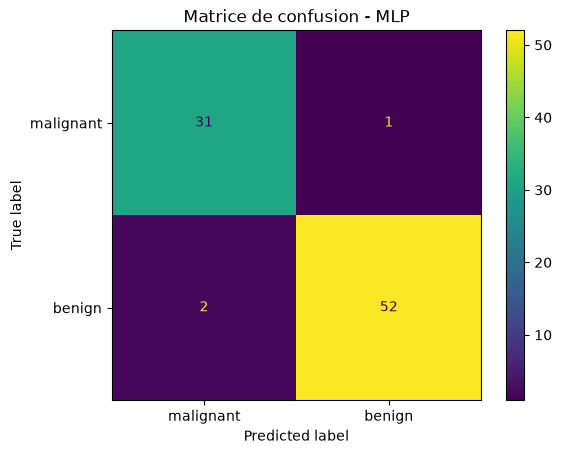

In [30]:
cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()
plt.title("Matrice de confusion - MLP")
plt.show()

In [31]:
torch.save(model.state_dict(), "best_mlp_model.pth")
print("Modèle MLP final sauvegardé avec succès.")

Modèle MLP final sauvegardé avec succès.


### Résultats finaux sur le test set

L’évaluation finale du modèle MLP sur le test set donne les résultats suivants :

- Accuracy : 0.9651
- Precision : 0.9811
- Recall : 0.9630
- F1-score : 0.9720

Ces résultats montrent que le modèle généralise correctement sur des données non vues pendant l’entraînement. L’accuracy de 0.9651 indique que le modèle classe correctement environ 96,5 % des observations du test set.

La précision de 0.9811 montre que les prédictions positives du modèle sont très fiables. Le rappel de 0.9630 indique que le modèle détecte correctement la majorité des exemples positifs. Enfin, le F1-score de 0.9720 confirme un bon équilibre entre précision et rappel.

Ces performances confirment que le MLP est une architecture pertinente pour ce dataset tabulaire, à condition d’appliquer un prétraitement correct, notamment la normalisation des variables numériques. Toutefois, le MLP reste limité par son absence de biais inductif spécifique : il ne modélise ni la structure spatiale des images, ni la dépendance temporelle des séquences.